In [18]:
# Cellule 1 : installation (Colab). Redémarre l'exécution si scikit-learn est mis à jour.
!pip install -q interpret openpyxl
import sklearn; print('scikit-learn', sklearn.__version__)  # >= 1.4 requis

scikit-learn 1.6.1


In [19]:
# Cellule 2 : imports et configuration
import time, warnings, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint, chi2_contingency

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, f1_score,
                             make_scorer, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

try:
    from interpret.glassbox import ExplainableBoostingClassifier
    HAS_EBM = True
except ImportError:
    HAS_EBM = False
    print("interpret n'est pas installé : l'EBM sera ignoré")

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)

DATA_PATH = '/content/CVD_cleaned.csv' if Path('/content').exists() else 'CVD_cleaned.csv'
OUT = Path('outputs')
(OUT / 'tables').mkdir(parents=True, exist_ok=True)
(OUT / 'figures').mkdir(parents=True, exist_ok=True)

FAST_MODE = True      # Activé pour garantir une exécution complète et rapide sans interruption
EBM_SEARCH_N = 10000   # Échantillon restreint pour accélérer l'EBM en mode rapide

NUM_COLS = ['Height_(cm)', 'Weight_(kg)', 'BMI', 'Alcohol_Consumption',
            'Fruit_Consumption', 'Green_Vegetables_Consumption', 'FriedPotato_Consumption']
ORDER = {
    'General_Health': ['Poor', 'Fair', 'Good', 'Very Good', 'Excellent'],
    'Checkup': ['Never', '5 or more years ago', 'Within the past 5 years',
                'Within the past 2 years', 'Within the past year'],
    'Age_Category': ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54',
                     '55-59', '60-64', '65-69', '70-74', '75-79', '80+'],
}

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False})

def is_cat(s):
    return not pd.api.types.is_numeric_dtype(s)

def save_fig(fig, filename, caption):
    fig.savefig(OUT / 'figures' / f'{filename}.png')
    plt.show()

# 1. Chargement et nettoyage minimal

In [20]:
df = pd.read_csv(DATA_PATH)
print('Dimensions :', df.shape)
display(df.head())
df.info()

miss = df.isnull().sum()
print('\nValeurs manquantes :')
print(miss[miss > 0] if miss.any() else 'Aucune valeur manquante')

print('\nValeurs des variables catégorielles :')
for c in df.select_dtypes(exclude='number').columns:
    print(f'\n--- {c} ---')
    print(df[c].value_counts(dropna=False))

Dimensions : (308854, 19)


,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,Poor,Within the past 2 years,No,No,No,No,No,No,Yes,Female,70-74,150.0,32.66,14.54,Yes,0.0,30.0,16.0,12.0
1,Very Good,Within the past year,No,Yes,No,No,No,Yes,No,Female,70-74,165.0,77.11,28.29,No,0.0,30.0,0.0,4.0
2,Very Good,Within the past year,Yes,No,No,No,No,Yes,No,Female,60-64,163.0,88.45,33.47,No,4.0,12.0,3.0,16.0
3,Poor,Within the past year,Yes,Yes,No,No,No,Yes,No,Male,75-79,180.0,93.44,28.73,No,0.0,30.0,30.0,8.0
4,Good,Within the past year,No,No,No,No,No,No,No,Male,80+,191.0,88.45,24.37,Yes,0.0,8.0,4.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308854 entries, 0 to 308853
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   General_Health                308854 non-null  object 
 1   Checkup                       308854 non-null  object 
 2   Exercise                      308854 non-null  object 
 3   Heart_Disease                 308854 non-null  object 
 4   Skin_Cancer                   308854 non-null  object 
 5   Other_Cancer                  308854 non-null  object 
 6   Depression                    308854 non-null  object 
 7   Diabetes                      308854 non-null  object 
 8   Arthritis                     308854 non-null  object 
 9   Sex                           308854 non-null  object 
 10  Age_Category                  308854 non-null  object 
 11  Height_(cm)                   308854 non-null  float64
 12  Weight_(kg)                   308854 non-nul

In [21]:
# Rechargement à la source pour garantir la réexécutabilité de la cellule
df = pd.read_csv(DATA_PATH)
n0 = len(df)

# 1. Suppression rigoureuse des doublons
df = df.drop_duplicates().reset_index(drop=True)
print(f'Doublons supprimés : {n0 - len(df)}')

# 2. Cohérence physique stricte (Poids / Taille / IMC)
# Détection des IMC totalement incohérents par rapport au poids et à la taille déclarés
# IMC théorique = Poids (kg) / (Taille (m))^2
imc_theorique = df['Weight_(kg)'] / ((df['Height_(cm)'] / 100) ** 2)
ecart_imc = (df['BMI'] - imc_theorique).abs()

# On élimine les lignes présentant une incohérence majeure (plus de 5 points d'IMC d'écart)
incoherences_imc = ecart_imc > 5
print(f'Lignes avec IMC physiquement incohérent supprimées : {incoherences_imc.sum()}')
df = df[~incoherences_imc].reset_index(drop=True)

# 3. Traitement robuste des valeurs aberrantes (écrêtage par bornes cliniques absolues)
# Ces limites physiologiques et de consommation évitent d'apprendre des statistiques sur l'ensemble du dataset
df['Height_(cm)'] = df['Height_(cm)'].clip(120, 230)
df['Weight_(kg)'] = df['Weight_(kg)'].clip(30, 250)
df['BMI'] = df['BMI'].clip(15, 60)

# Consommations alimentaires : écrêtage des valeurs aberrantes extrêmes (ex: fréquences journalières démesurées)
df['Alcohol_Consumption'] = df['Alcohol_Consumption'].clip(0, 30)
df['Fruit_Consumption'] = df['Fruit_Consumption'].clip(0, 120)
df['Green_Vegetables_Consumption'] = df['Green_Vegetables_Consumption'].clip(0, 120)
df['FriedPotato_Consumption'] = df['FriedPotato_Consumption'].clip(0, 120)

# 4. Encodage de la variable cible binaire
df['target'] = (df['Heart_Disease'] == 'Yes').astype(int)
df = df.drop(columns='Heart_Disease')

print('\n--- Rapport de fin de nettoyage minimal & traitement des valeurs aberrantes ---')
print('Dimensions finales du dataset :', df.shape)
print('Prévalence de la maladie cardiaque :', round(df['target'].mean(), 4))
display(df.describe().T)

Doublons supprimés : 80
Lignes avec IMC physiquement incohérent supprimées : 0

--- Rapport de fin de nettoyage minimal & traitement des valeurs aberrantes ---
Dimensions finales du dataset : (308774, 19)
Prévalence de la maladie cardiaque : 0.0809


,count,mean,std,min,25%,50%,75%,max
Height_(cm),308774.0,170.618815,10.637566,120.0,163.00,170.00,178.00,230.0
Weight_(kg),308774.0,83.589291,21.334662,30.0,68.04,81.65,95.25,250.0
BMI,308774.0,28.613095,6.432537,15.0,24.21,27.44,31.85,60.0
Alcohol_Consumption,308774.0,5.097557,8.200434,0.0,0.00,1.00,6.00,30.0
Fruit_Consumption,308774.0,29.834290,24.877812,0.0,12.00,30.00,30.00,120.0
Green_Vegetables_Consumption,308774.0,15.109465,14.926537,0.0,4.00,12.00,20.00,120.0
FriedPotato_Consumption,308774.0,6.297172,8.582952,0.0,2.00,4.00,8.00,120.0
target,308774.0,0.080871,0.272638,0.0,0.00,0.00,0.00,1.0


```markdown
## 2. Séparation dev / test
```

In [22]:
def strat_key(d):
    key = d['target'].astype(str) + '|' + d['Sex'] + '|' + d['Age_Category']
    rare = key.map(key.value_counts()) < 10
    return key.where(~rare, d['target'].astype(str))

dev, test = train_test_split(df, test_size=0.20, stratify=strat_key(df), random_state=SEED)
dev = dev.reset_index(drop=True)
test = test.reset_index(drop=True)

print('Dev :', dev.shape, '| Test :', test.shape)
chk = pd.DataFrame({
    'Prévalence cible': [dev['target'].mean(), test['target'].mean()],
    '% Hommes': [(dev['Sex'] == 'Male').mean(), (test['Sex'] == 'Male').mean()],
    '% 65 ans et plus': [dev['Age_Category'].isin(['65-69', '70-74', '75-79', '80+']).mean(),
                         test['Age_Category'].isin(['65-69', '70-74', '75-79', '80+']).mean()],
}, index=['Dev', 'Test']).round(4)
display(chk)
chk.to_excel(OUT / 'tables' / 'tableau_dev_test_repartition.xlsx')

Dev : (247019, 19) | Test : (61755, 19)


,Prévalence cible,% Hommes,% 65 ans et plus
Dev,0.0809,0.4813,0.3481
Test,0.0809,0.4813,0.3481


# 3. Exploration des données

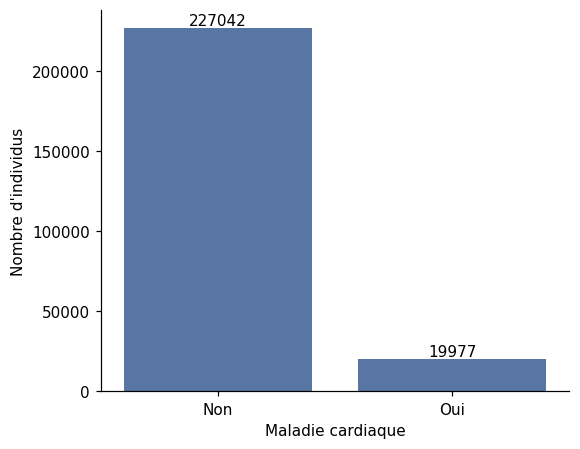

In [23]:
# Figure 1 : distribution de la cible
fig, ax = plt.subplots(figsize=(5.5, 4.5))
order = ['Non', 'Oui']
sns.countplot(x=dev['target'].map({0: 'Non', 1: 'Oui'}), order=order, ax=ax, color='#4C72B0')
ax.bar_label(ax.containers[0])
ax.set_xlabel('Maladie cardiaque')
ax.set_ylabel("Nombre d'individus")
save_fig(fig, 'fig01_distribution_cible', '')

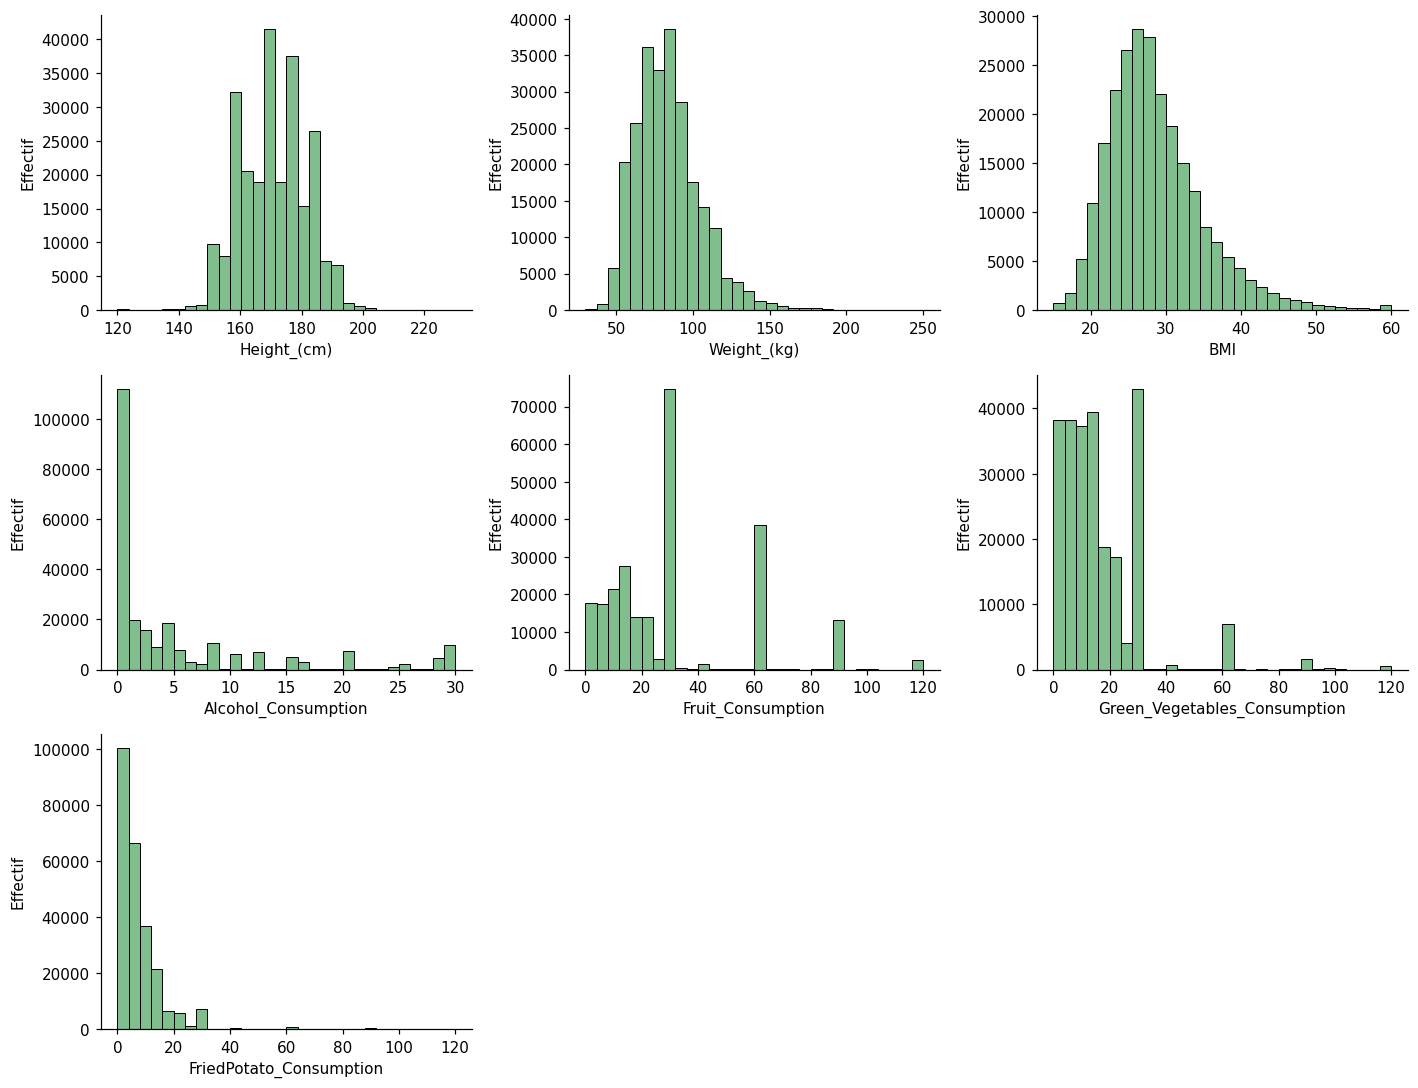

In [24]:
# Figure 2 : distributions des variables numériques
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, c in zip(axes.ravel(), NUM_COLS):
    sns.histplot(dev[c], bins=30, ax=ax, color='#55A868')
    ax.set_xlabel(c)
    ax.set_ylabel('Effectif')
for ax in axes.ravel()[len(NUM_COLS):]:
    ax.axis('off')
fig.tight_layout()
save_fig(fig, 'fig02_distributions_numeriques', '')

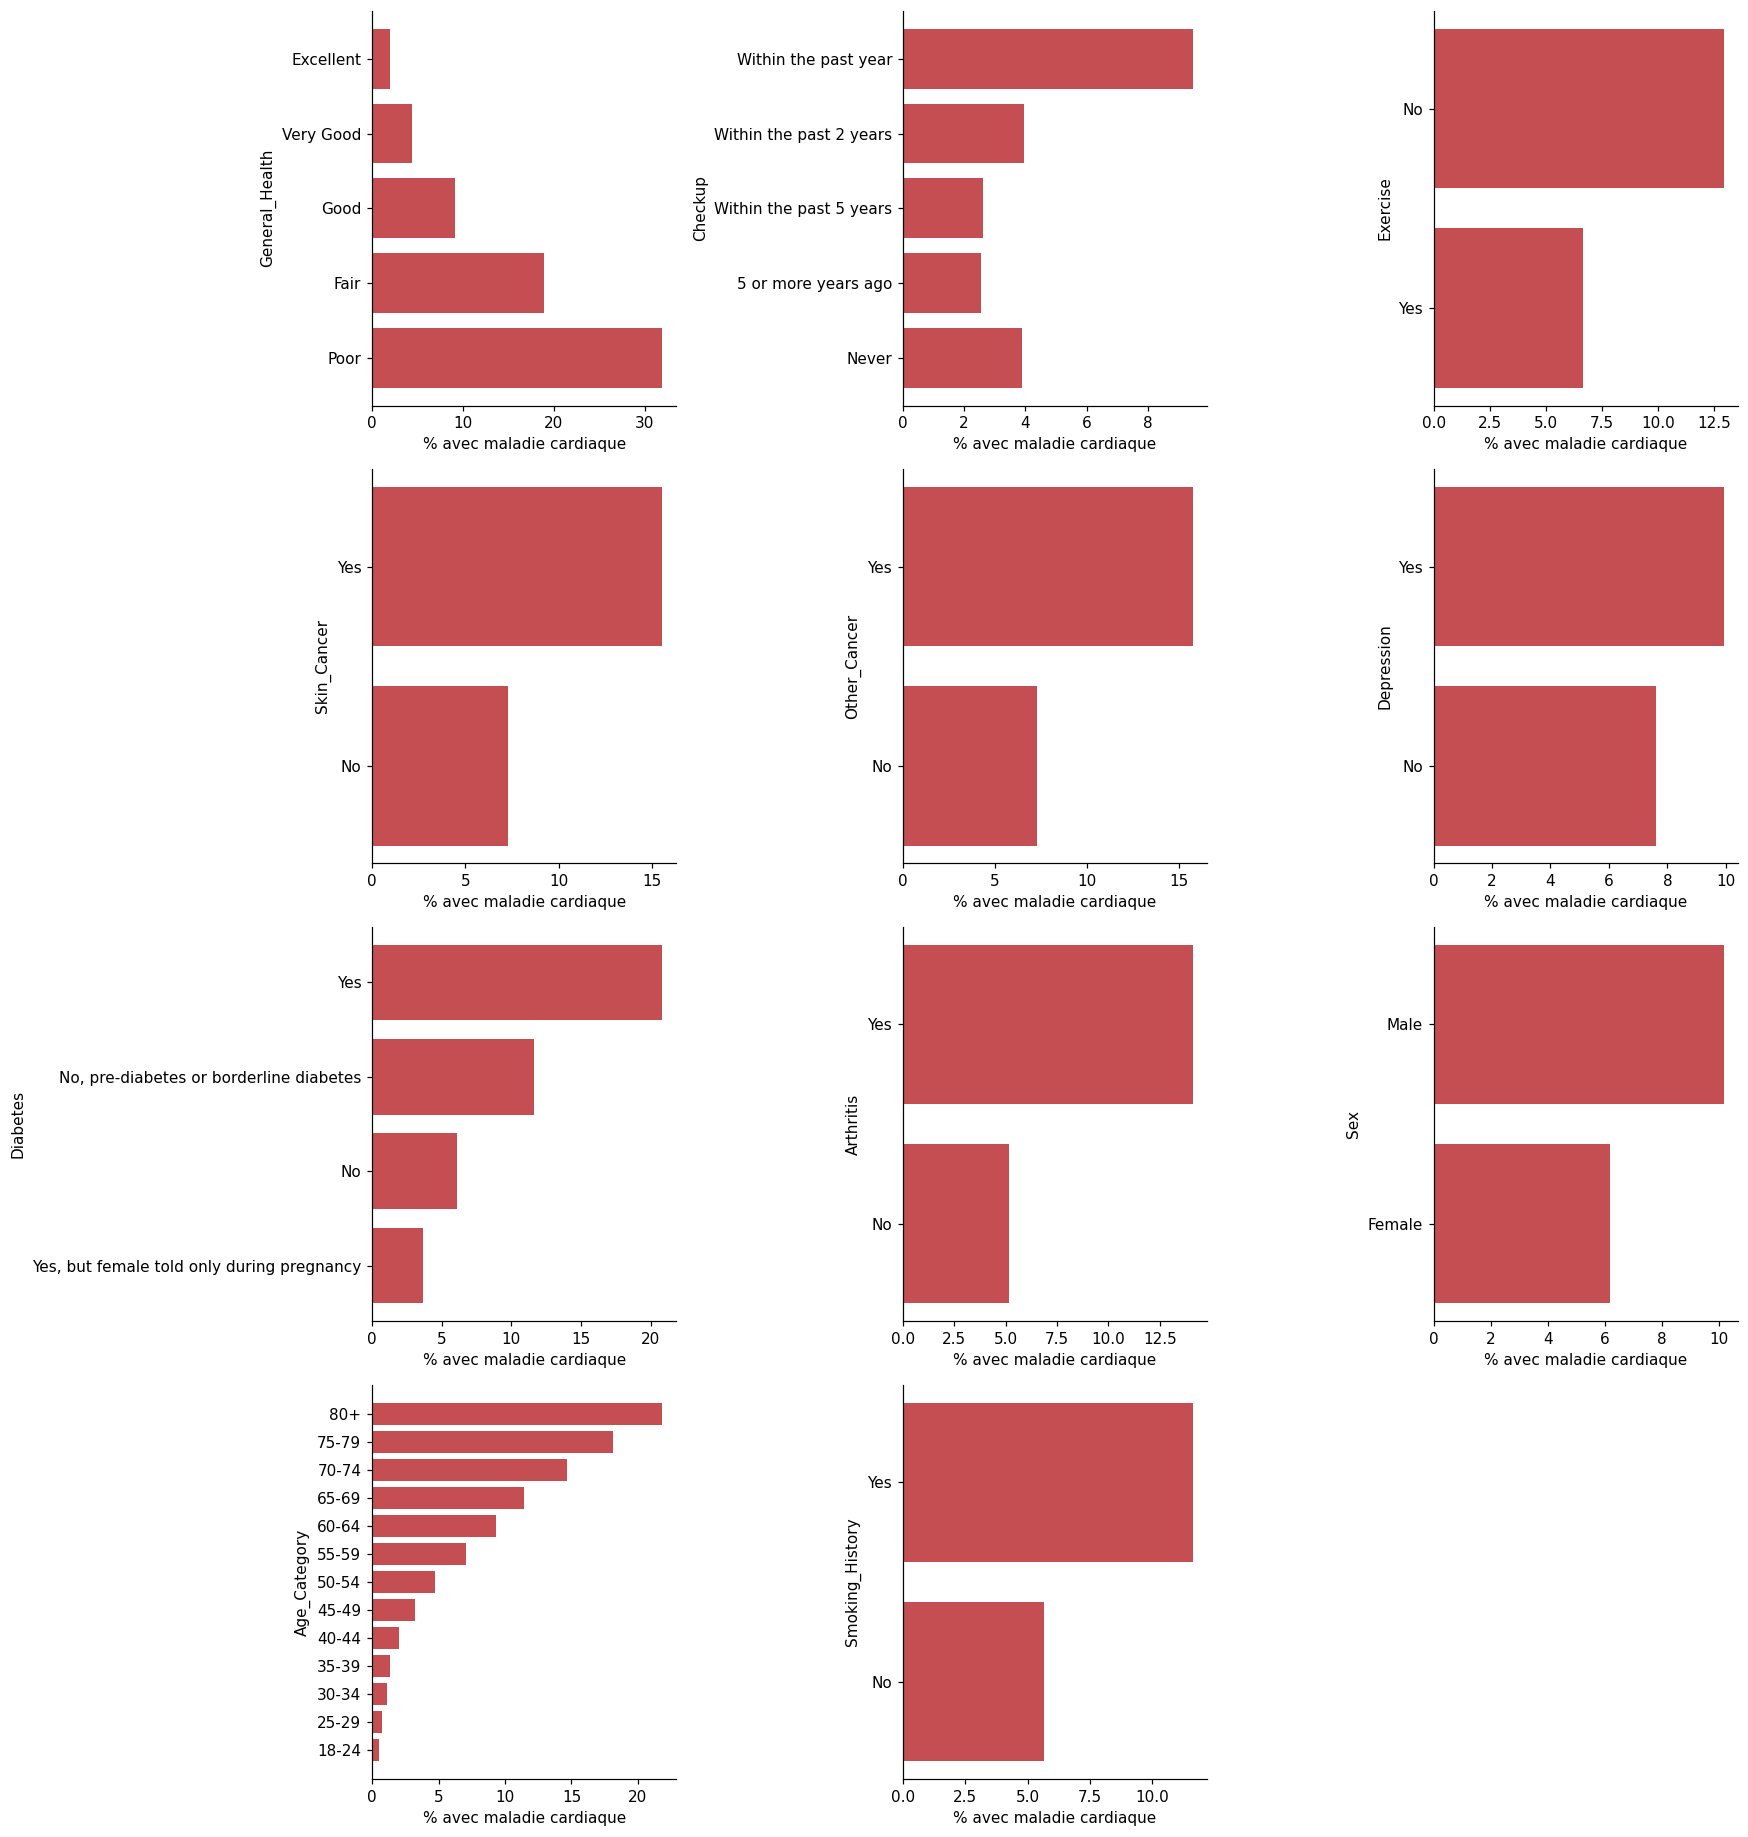

In [25]:
# Figure 3 : proportion de maladie cardiaque selon chaque variable catégorielle
cat_eda = [c for c in dev.columns if is_cat(dev[c])]
ncols = 3
nrows = int(np.ceil(len(cat_eda) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.2 * nrows))
for ax, c in zip(axes.ravel(), cat_eda):
    prop = dev.groupby(c)['target'].mean()
    prop = prop.reindex(ORDER[c]) if c in ORDER else prop.sort_values()
    ax.barh(prop.index.astype(str), prop.values * 100, color='#C44E52')
    ax.set_xlabel('% avec maladie cardiaque')
    ax.set_ylabel(c)
for ax in axes.ravel()[len(cat_eda):]:
    ax.axis('off')
fig.tight_layout()
save_fig(fig, 'fig03_proportion_par_categorie', '')

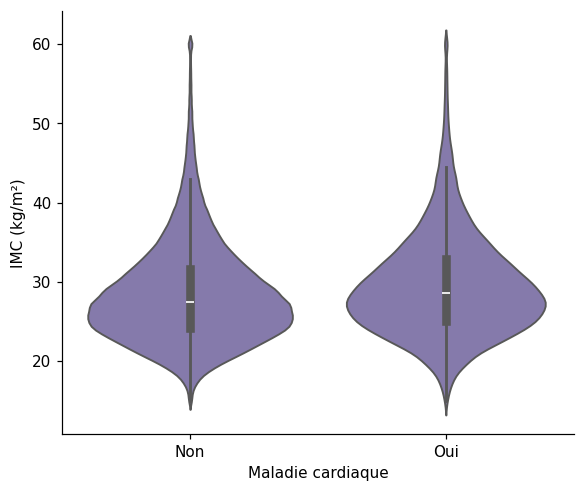

In [26]:
# Figure 4 : IMC selon le statut cardiaque
fig, ax = plt.subplots(figsize=(6, 5))
sns.violinplot(x=dev['target'].map({0: 'Non', 1: 'Oui'}), y=dev['BMI'], order=['Non', 'Oui'],
               ax=ax, color='#8172B3')
ax.set_xlabel('Maladie cardiaque')
ax.set_ylabel('IMC (kg/m²)')
save_fig(fig, 'fig04_imc_selon_cible', '')

# 4. Corrélations et multicolinéarité

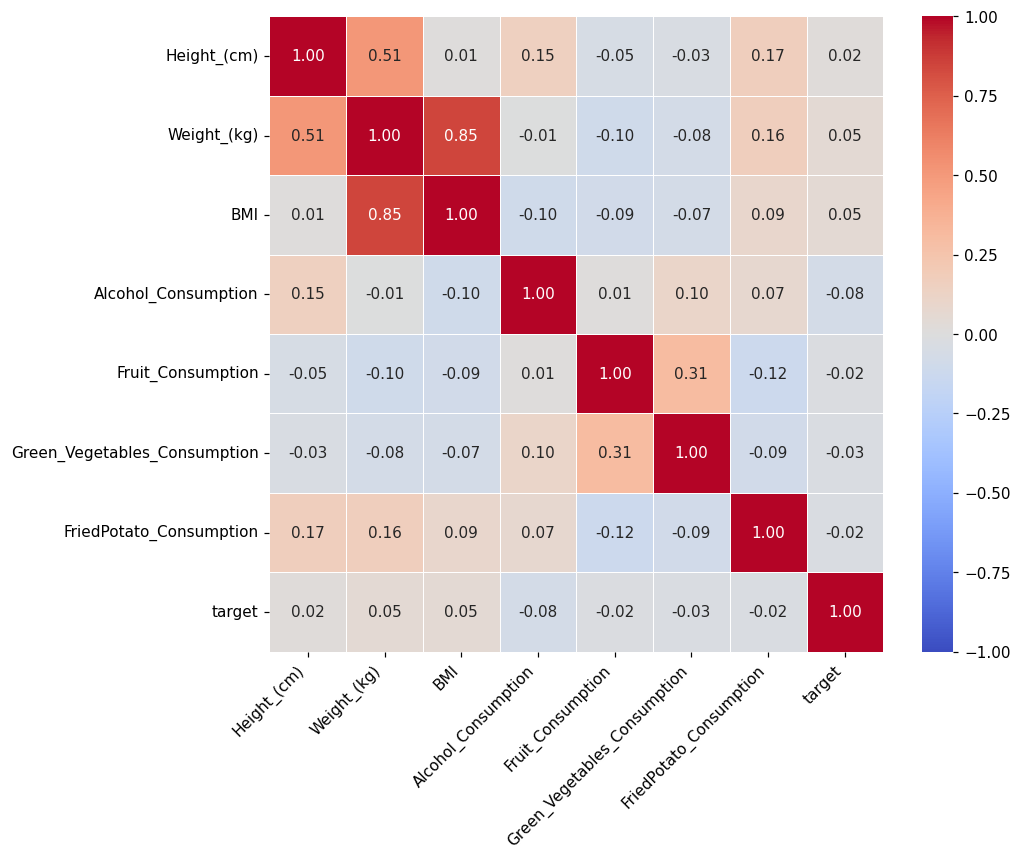

,Variable,VIF
1,Weight_(kg),61.54
2,BMI,47.76
0,Height_(cm),16.02
4,Fruit_Consumption,1.09
5,Green_Vegetables_Consumption,1.09
3,Alcohol_Consumption,1.03
6,FriedPotato_Consumption,1.02


In [27]:
# Figure 5 : corrélations (Spearman) entre variables numériques
corr = dev[NUM_COLS + ['target']].corr(method='spearman')
corr.round(2).to_excel(OUT / 'tables' / 'tableau_correlations_numeriques.xlsx')

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=.5, ax=ax)
plt.xticks(rotation=45, ha='right')
save_fig(fig, 'fig05_correlations_numeriques', '')

# VIF calculé à la main : VIF_j = 1 / (1 - R2_j)
def compute_vif(d, cols):
    rows = []
    for c in cols:
        others = [x for x in cols if x != c]
        r2 = LinearRegression().fit(d[others], d[c]).score(d[others], d[c])
        rows.append({'Variable': c, 'VIF': 1 / max(1 - r2, 1e-12)})
    return pd.DataFrame(rows).sort_values('VIF', ascending=False)

vif = compute_vif(dev, NUM_COLS).round(2)
display(vif)
vif.to_excel(OUT / 'tables' / 'tableau_vif.xlsx', index=False)

Paires de variables catégorielles avec V >= 0.3 :


,Variable 1,Variable 2,V de Cramér
57,Arthritis,Age_Category,0.374018


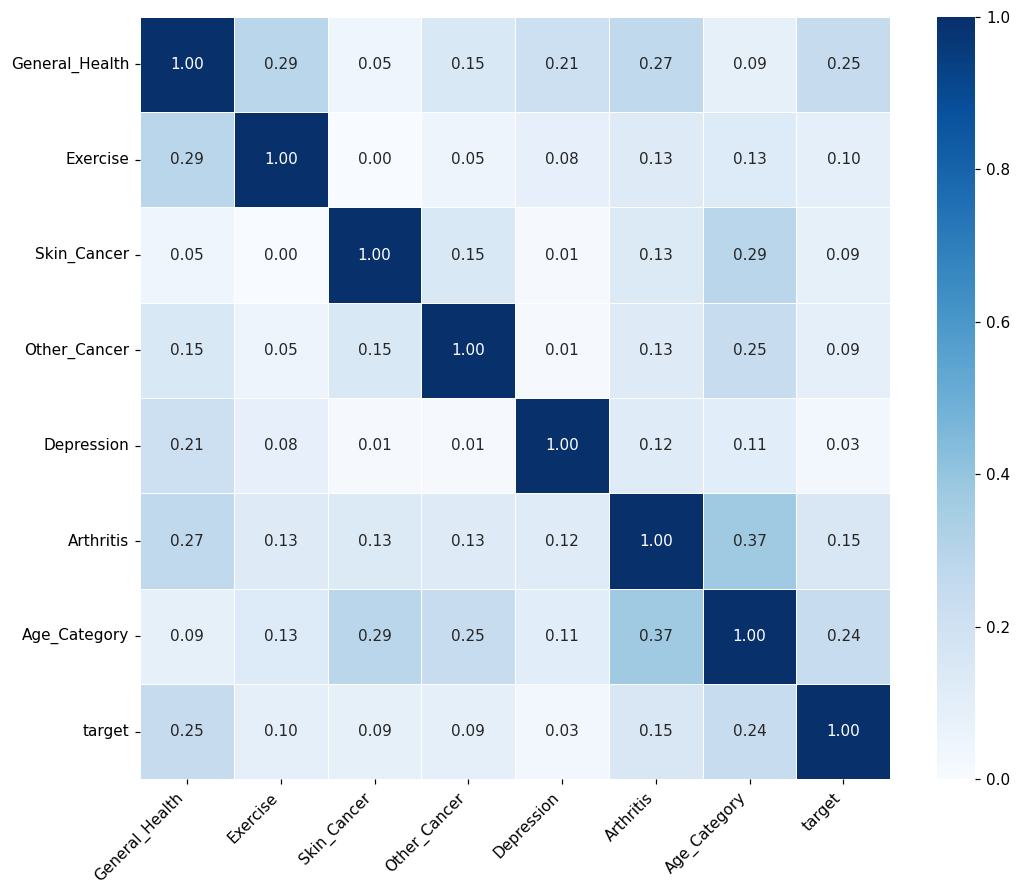

In [28]:
# V de Cramér entre variables catégorielles (et la cible)
cat_all = [c for c in dev.columns if is_cat(dev[c])] + ['target']

def cramers_v(a, b):
    t = pd.crosstab(a, b)
    k = min(t.shape) - 1
    return np.sqrt(chi2_contingency(t)[0] / (t.values.sum() * k)) if k > 0 else np.nan

cv_mat = pd.DataFrame([[cramers_v(dev[a], dev[b]) for b in cat_all] for a in cat_all],
                      index=cat_all, columns=cat_all)
cv_mat.round(2).to_excel(OUT / 'tables' / 'tableau_cramers_v.xlsx')

# Paires fortement associées (V >= 0.3), hors cible
pairs = (cv_mat.where(np.triu(np.ones(cv_mat.shape, dtype=bool), k=1))
         .stack().rename('V de Cramér').reset_index())
pairs.columns = ['Variable 1', 'Variable 2', 'V de Cramér']
strong = pairs[(pairs['V de Cramér'] >= 0.3) & (pairs['Variable 1'] != 'target')
               & (pairs['Variable 2'] != 'target')].sort_values('V de Cramér', ascending=False)
print('Paires de variables catégorielles avec V >= 0.3 :')
display(strong if len(strong) else 'Aucune paire au-dessus de 0.3')
strong.round(3).to_excel(OUT / 'tables' / 'tableau_paires_fortes_cramers_v.xlsx', index=False)

# Figure 6 : heatmap
off = cv_mat.drop(index='target', columns='target', errors='ignore')
keep = [c for c in off.columns if (off[c].drop(c) >= 0.2).any()] or list(off.columns)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cv_mat.loc[keep + ['target'], keep + ['target']], annot=True, fmt='.2f',
            cmap='Blues', vmin=0, vmax=1, linewidths=.5, ax=ax)
plt.xticks(rotation=45, ha='right')
save_fig(fig, 'fig06_cramers_v', '')

In [29]:
# DÉCISION : variables éliminées pour multicolinéarité (à justifier dans le mémoire avec Figure 5 et le tableau VIF)
# Exemple : BMI = poids / taille², donc Height_(cm) et Weight_(kg) sont redondants avec BMI.
DROP = ['Height_(cm)', 'Weight_(kg)']   # ajuste selon les VIF et corrélations observés ci-dessus

print('Variables éliminées :', DROP)
print('VIF avant élimination :')
display(vif)
dev = dev.drop(columns=DROP)
test = test.drop(columns=DROP)
NUM_USED = [c for c in NUM_COLS if c not in DROP]
print('\nVIF après élimination :')
display(compute_vif(dev, NUM_USED).round(2))

Variables éliminées : ['Height_(cm)', 'Weight_(kg)']
VIF avant élimination :


,Variable,VIF
1,Weight_(kg),61.54
2,BMI,47.76
0,Height_(cm),16.02
4,Fruit_Consumption,1.09
5,Green_Vegetables_Consumption,1.09
3,Alcohol_Consumption,1.03
6,FriedPotato_Consumption,1.02



VIF après élimination :


,Variable,VIF
2,Fruit_Consumption,1.09
3,Green_Vegetables_Consumption,1.09
0,BMI,1.02
1,Alcohol_Consumption,1.02
4,FriedPotato_Consumption,1.01


# 4.1 Traitement des valeurs aberrantes (IQR)

In [30]:
# Identification des valeurs aberrantes sur le jeu 'dev'
for col in NUM_USED:
    Q1 = dev[col].quantile(0.25)
    Q3 = dev[col].quantile(0.75)
    IQR = Q3 - Q1
    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    outliers = dev[(dev[col] < borne_inf) | (dev[col] > borne_sup)]
    print(f"{col} -> Limites : [{borne_inf:.2f}, {borne_sup:.2f}] | Nombre d'outliers détectés : {len(outliers)} ({len(outliers)/len(dev)*100:.2f}%)")

BMI -> Limites : [12.75, 43.31] | Nombre d'outliers détectés : 7611 (3.08%)
Alcohol_Consumption -> Limites : [-9.00, 15.00] | Nombre d'outliers détectés : 28870 (11.69%)
Fruit_Consumption -> Limites : [-15.00, 57.00] | Nombre d'outliers détectés : 54562 (22.09%)
Green_Vegetables_Consumption -> Limites : [-20.00, 44.00] | Nombre d'outliers détectés : 9494 (3.84%)
FriedPotato_Consumption -> Limites : [-7.00, 17.00] | Nombre d'outliers détectés : 15631 (6.33%)


In [31]:
# Application du traitement des valeurs aberrantes (écrêtage par IQR appris uniquement sur le jeu dev)
for col in NUM_USED:
    Q1 = dev[col].quantile(0.25)
    Q3 = dev[col].quantile(0.75)
    IQR = Q3 - Q1
    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    # Écrêtage (winsorisation) sur le dev
    dev[col] = dev[col].clip(borne_inf, borne_sup)
    # Écrêtage sur le test avec les mêmes seuils appris du dev (évite toute fuite de données)
    test[col] = test[col].clip(borne_inf, borne_sup)

print("Traitement par écrêtage IQR terminé avec succès sur dev et test.")
print("Voici un aperçu des statistiques descriptives après traitement des valeurs aberrantes sur dev :")
display(dev[NUM_USED].describe().T)

Traitement par écrêtage IQR terminé avec succès sur dev et test.
Voici un aperçu des statistiques descriptives après traitement des valeurs aberrantes sur dev :


,count,mean,std,min,25%,50%,75%,max
BMI,247019.0,28.448016,5.916529,15.0,24.21,27.44,31.85,43.31
Alcohol_Consumption,247019.0,3.934321,5.348699,0.0,0.00,1.00,6.00,15.00
Fruit_Consumption,247019.0,26.894826,18.724875,0.0,12.00,30.00,30.00,57.00
Green_Vegetables_Consumption,247019.0,14.142398,11.489006,0.0,4.00,12.00,20.00,44.00
FriedPotato_Consumption,247019.0,5.445974,5.047379,0.0,2.00,4.00,8.00,17.00


# 5. Variables et pipeline de prétraitement

In [32]:
ord_cols = list(ORDER)
num_cols = NUM_USED
cat_cols = [c for c in dev.columns if is_cat(dev[c]) and c not in ord_cols]
feats = ord_cols + num_cols + cat_cols

# Vérification des libellés ordinaux (évite une erreur au moment de l'encodage)
for c in ord_cols:
    inconnus = (set(df[c].unique()) - set(ORDER[c]))
    if inconnus:
        raise ValueError(f"Libellés absents de ORDER['{c}'] : {inconnus}")

X_dev, y_dev = dev[feats], dev['target']
X_test, y_test = test[feats], test['target']
print('Numériques :', num_cols)
print('Ordinales  :', ord_cols)
print('Nominales  :', cat_cols)

def make_prep():
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num_cols),
        ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('enc', OrdinalEncoder(categories=[ORDER[c] for c in ord_cols])),
                          ('sc', StandardScaler())]), ord_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(drop='first', handle_unknown='ignore',
                                               sparse_output=False))]), cat_cols),
    ])

Numériques : ['BMI', 'Alcohol_Consumption', 'Fruit_Consumption', 'Green_Vegetables_Consumption', 'FriedPotato_Consumption']
Ordinales  : ['General_Health', 'Checkup', 'Age_Category']
Nominales  : ['Exercise', 'Skin_Cancer', 'Other_Cancer', 'Depression', 'Diabetes', 'Arthritis', 'Sex', 'Smoking_History']


# 6. Validation croisée et recherche d'hyperparamètres

In [33]:
key_dev = strat_key(dev)
cv_splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_dev, key_dev))

def best_f1(y_true, proba):
    p, r, _ = precision_recall_curve(y_true, proba)
    return np.max(2 * p * r / np.clip(p + r, 1e-12, None))

def best_threshold(y, proba):
    p, r, th = precision_recall_curve(y, proba)
    f = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return th[np.argmax(f)]

try:
    scorer = make_scorer(best_f1, response_method='predict_proba')
except TypeError:                                   # anciennes versions de scikit-learn
    scorer = make_scorer(best_f1, needs_proba=True)

In [34]:
def with_prep(clf):
    return Pipeline([('prep', make_prep()), ('clf', clf)])

M_LR, M_DT, M_HGB, M_EBM = ('Régression logistique', 'Arbre de décision',
                            'HistGradientBoosting (boîte noire)', 'EBM')

MODELS = {
    M_LR: (with_prep(LogisticRegression(max_iter=1000)),
           {'clf__C': loguniform(1e-3, 1e2), 'clf__class_weight': [None, 'balanced']}, 15),
    M_DT: (with_prep(DecisionTreeClassifier(random_state=SEED)),
           {'clf__max_depth': randint(3, 12), 'clf__min_samples_leaf': randint(20, 500),
            'clf__class_weight': [None, 'balanced']}, 20),
    M_HGB: (with_prep(HistGradientBoostingClassifier(random_state=SEED)),
            {'clf__learning_rate': loguniform(0.02, 0.3), 'clf__max_leaf_nodes': randint(8, 64),
             'clf__l2_regularization': loguniform(1e-3, 10)}, 15),
}
if HAS_EBM:   # glassbox : gère lui-même les variables catégorielles
    MODELS[M_EBM] = (ExplainableBoostingClassifier(random_state=SEED, n_jobs=-1, outer_bags=4),
                     {'learning_rate': loguniform(0.005, 0.05), 'max_leaves': [2, 3, 4],
                      'min_samples_leaf': randint(10, 200), 'interactions': [0, 5, 10]}, 8)

if FAST_MODE:
    MODELS = {k: (e, s, 2) for k, (e, s, n) in MODELS.items()}

fitted, oof, thr, best_params, cv_scores = {}, {}, {}, {}, {}

for name, (est, space, n_iter) in MODELS.items():
    t0 = time.time()
    is_ebm = (name == M_EBM)
    if is_ebm and EBM_SEARCH_N and EBM_SEARCH_N < len(X_dev):
        # l'EBM est lent : on règle les hyperparamètres sur un sous-échantillon stratifié du dev
        idx, _ = train_test_split(np.arange(len(X_dev)), train_size=EBM_SEARCH_N,
                                  stratify=key_dev, random_state=SEED)
        Xs, ys, ks = X_dev.iloc[idx], y_dev.iloc[idx], key_dev.iloc[idx]
        cv_s = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(Xs, ks))
        search = RandomizedSearchCV(est, space, n_iter=n_iter, scoring=scorer, cv=cv_s,
                                    random_state=SEED, n_jobs=1)
        search.fit(Xs, ys)
        best = clone(est).set_params(**search.best_params_).fit(X_dev, y_dev)  # réentraîné sur tout le dev
    else:
        search = RandomizedSearchCV(est, space, n_iter=n_iter, scoring=scorer, cv=cv_splits,
                                    refit=True, random_state=SEED, n_jobs=1 if is_ebm else -1)
        search.fit(X_dev, y_dev)
        best = search.best_estimator_                    # déjà réentraîné sur tout le dev
    fitted[name] = best
    best_params[name] = search.best_params_
    cv_scores[name] = search.best_score_
    oof[name] = cross_val_predict(clone(best), X_dev, y_dev, cv=cv_splits,
                                  method='predict_proba')[:, 1]
    thr[name] = best_threshold(y_dev, oof[name])
    print(f'{name:38s} F1(CV)={search.best_score_:.4f} | seuil={thr[name]:.3f} | {time.time()-t0:.0f}s')
    print('   meilleurs hyperparamètres :', search.best_params_)

Régression logistique                  F1(CV)=0.3711 | seuil=0.171 | 36s
   meilleurs hyperparamètres : {'clf__C': np.float64(0.0745934328572655), 'clf__class_weight': None}
Arbre de décision                      F1(CV)=0.3636 | seuil=0.190 | 40s
   meilleurs hyperparamètres : {'clf__class_weight': None, 'clf__max_depth': 10, 'clf__min_samples_leaf': 208}
HistGradientBoosting (boîte noire)     F1(CV)=0.3735 | seuil=0.181 | 72s
   meilleurs hyperparamètres : {'clf__l2_regularization': np.float64(1.3145103232150122), 'clf__learning_rate': np.float64(0.10068858772001629), 'clf__max_leaf_nodes': 26}
EBM                                    F1(CV)=0.3619 | seuil=0.175 | 252s
   meilleurs hyperparamètres : {'interactions': 10, 'learning_rate': np.float64(0.03129774092143768), 'max_leaves': 4, 'min_samples_leaf': 116}


# 7. Évaluation sur l'ensemble de test

In [35]:
def metrics(y, p, t):
    pred = (p >= t).astype(int)
    return {'F1': f1_score(y, pred),
            'Précision': precision_score(y, pred, zero_division=0),
            'Rappel': recall_score(y, pred),
            'Accuracy équilibrée': balanced_accuracy_score(y, pred),
            'ROC-AUC': roc_auc_score(y, p),
            'PR-AUC': average_precision_score(y, p),
            'Seuil': t}

# Validation : prédictions out-of-fold sur le dev
val_tab = pd.DataFrame([{'Modèle': n, **metrics(y_dev, oof[n], thr[n])} for n in fitted])
val_tab['Hyperparamètres'] = [str(best_params[n]) for n in fitted]

# Test : une seule évaluation
proba_test = {n: m.predict_proba(X_test)[:, 1] for n, m in fitted.items()}
test_tab = pd.DataFrame([{'Modèle': n, **metrics(y_test, proba_test[n], thr[n])} for n in fitted])

final = val_tab.drop(columns='Hyperparamètres').merge(
    test_tab, on='Modèle', suffixes=(' (validation)', ' (test)'))

print('VALIDATION (out-of-fold sur le dev)')
display(val_tab.drop(columns='Hyperparamètres').round(4))
print('TEST (une seule fois)')
display(test_tab.round(4))
print('VALIDATION vs TEST')
display(final.round(4))

with pd.ExcelWriter(OUT / 'tables' / 'tableau_resultats.xlsx') as xw:
    val_tab.round(4).to_excel(xw, sheet_name='validation', index=False)
    test_tab.round(4).to_excel(xw, sheet_name='test', index=False)
    final.round(4).to_excel(xw, sheet_name='validation_vs_test', index=False)

VALIDATION (out-of-fold sur le dev)


,Modèle,F1,Précision,Rappel,Accuracy équilibrée,ROC-AUC,PR-AUC,Seuil
0,Régression logistique,0.3697,0.2887,0.5138,0.7012,0.8347,0.3071,0.1708
1,Arbre de décision,0.3625,0.2843,0.4999,0.6946,0.8255,0.2925,0.1901
2,HistGradientBoosting (boîte noire),0.3726,0.2865,0.5325,0.7079,0.8365,0.3081,0.1811
3,EBM,0.3722,0.2859,0.5331,0.7080,0.8366,0.3087,0.1747


TEST (une seule fois)


,Modèle,F1,Précision,Rappel,Accuracy équilibrée,ROC-AUC,PR-AUC,Seuil
0,Régression logistique,0.3675,0.2869,0.5110,0.6996,0.8356,0.3106,0.1708
1,Arbre de décision,0.3562,0.2780,0.4954,0.6911,0.8268,0.2913,0.1901
2,HistGradientBoosting (boîte noire),0.3736,0.2889,0.5284,0.7070,0.8381,0.3113,0.1811
3,EBM,0.3723,0.2867,0.5308,0.7073,0.8375,0.3102,0.1747


VALIDATION vs TEST


,Modèle,F1 (validation),Précision (validation),Rappel (validation),Accuracy équilibrée (validation),ROC-AUC (validation),PR-AUC (validation),Seuil (validation),F1 (test),Précision (test),Rappel (test),Accuracy équilibrée (test),ROC-AUC (test),PR-AUC (test),Seuil (test)
0,Régression logistique,0.3697,0.2887,0.5138,0.7012,0.8347,0.3071,0.1708,0.3675,0.2869,0.5110,0.6996,0.8356,0.3106,0.1708
1,Arbre de décision,0.3625,0.2843,0.4999,0.6946,0.8255,0.2925,0.1901,0.3562,0.2780,0.4954,0.6911,0.8268,0.2913,0.1901
2,HistGradientBoosting (boîte noire),0.3726,0.2865,0.5325,0.7079,0.8365,0.3081,0.1811,0.3736,0.2889,0.5284,0.7070,0.8381,0.3113,0.1811
3,EBM,0.3722,0.2859,0.5331,0.7080,0.8366,0.3087,0.1747,0.3723,0.2867,0.5308,0.7073,0.8375,0.3102,0.1747


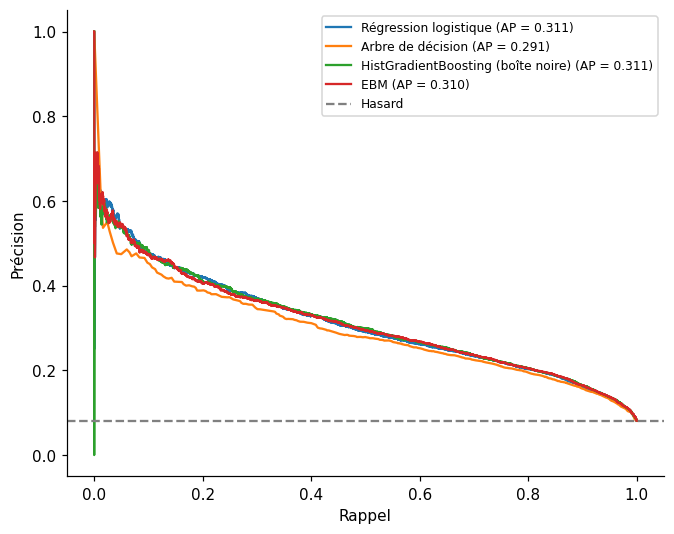

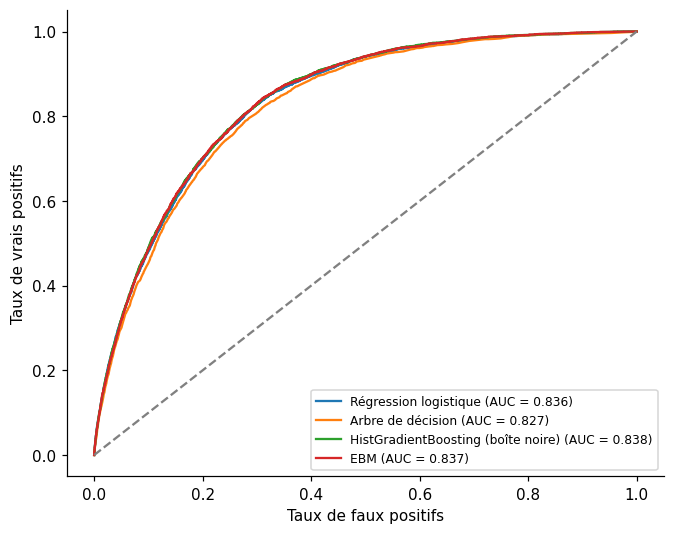

In [36]:
# Figure 7 : courbes précision-rappel ; Figure 8 : courbes ROC (test)
fig, ax = plt.subplots(figsize=(7, 5.5))
for n, p in proba_test.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, label=f'{n} (AP = {average_precision_score(y_test, p):.3f})')
ax.axhline(y_test.mean(), ls='--', color='grey', label='Hasard')
ax.set_xlabel('Rappel')
ax.set_ylabel('Précision')
ax.legend(fontsize=8)
save_fig(fig, 'fig07_courbes_pr_test',
         'Figure 7 : Courbes précision-rappel des modèles sur l’ensemble de test')

fig, ax = plt.subplots(figsize=(7, 5.5))
for n, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f'{n} (AUC = {roc_auc_score(y_test, p):.3f})')
ax.plot([0, 1], [0, 1], ls='--', color='grey')
ax.set_xlabel('Taux de faux positifs')
ax.set_ylabel('Taux de vrais positifs')
ax.legend(fontsize=8)
save_fig(fig, 'fig08_courbes_roc_test',
         'Figure 8 : Courbes ROC des modèles sur l’ensemble de test')

# 8. Performances par sous-groupes

,Modèle,Variable,Groupe,n,Prévalence,Rappel,Précision,F1,ROC-AUC
0,Régression logistique,Sex,Female,32033,0.062,0.376,0.257,0.306,0.828
1,Régression logistique,Sex,Male,29722,0.101,0.600,0.301,0.401,0.832
2,Régression logistique,Age_Category,18-24,3735,0.005,0.000,0.000,0.000,0.711
3,Régression logistique,Age_Category,25-29,3099,0.007,0.000,0.000,0.000,0.753
4,Régression logistique,Age_Category,30-34,3685,0.011,0.000,0.000,0.000,0.733
5,Régression logistique,Age_Category,35-39,4119,0.013,0.000,0.000,0.000,0.769
6,Régression logistique,Age_Category,40-44,4317,0.020,0.046,0.190,0.074,0.799
7,Régression logistique,Age_Category,45-49,4192,0.032,0.104,0.233,0.144,0.794
8,Régression logistique,Age_Category,50-54,5018,0.047,0.153,0.229,0.183,0.780
9,Régression logistique,Age_Category,55-59,5610,0.071,0.271,0.260,0.266,0.764


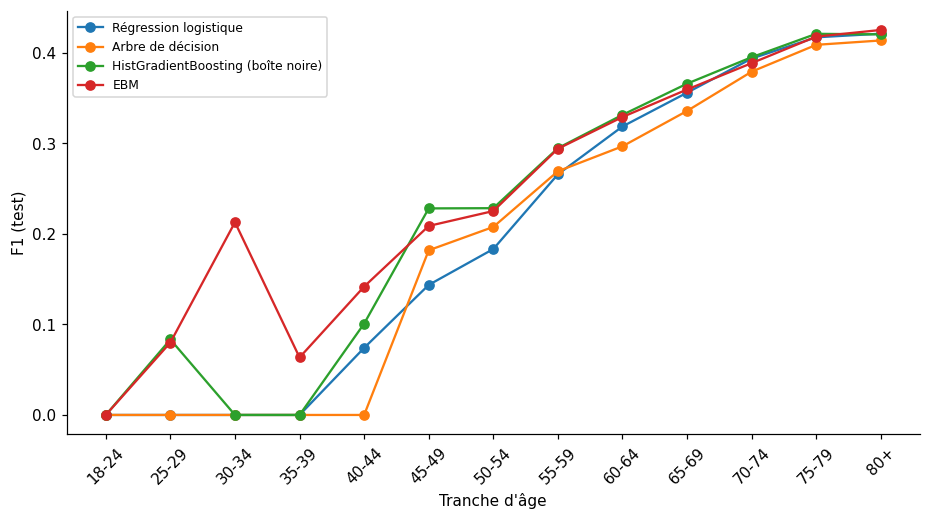

In [37]:
def subgroup_table(name, group_col):
    p, rows = proba_test[name], []
    for g, idx in X_test.groupby(group_col).groups.items():
        pos = np.asarray(idx)                      # index remis à zéro => positions
        yt, pp = y_test.iloc[pos], p[pos]
        ok = yt.nunique() == 2
        m = metrics(yt, pp, thr[name]) if ok else {}
        rows.append({'Modèle': name, 'Variable': group_col, 'Groupe': g, 'n': len(pos),
                     'Prévalence': yt.mean(), 'Rappel': m.get('Rappel'),
                     'Précision': m.get('Précision'), 'F1': m.get('F1'),
                     'ROC-AUC': m.get('ROC-AUC')})
    return pd.DataFrame(rows)

sub = pd.concat([subgroup_table(n, g) for n in fitted for g in ['Sex', 'Age_Category']],
                ignore_index=True)
sub.round(4).to_excel(OUT / 'tables' / 'tableau_sous_groupes.xlsx', index=False)
display(sub.round(3))

# Figure 9 : F1 par tranche d'âge
fig, ax = plt.subplots(figsize=(10, 5))
for n in fitted:
    s = sub[(sub['Modèle'] == n) & (sub['Variable'] == 'Age_Category')].set_index('Groupe')
    s = s.reindex(ORDER['Age_Category'])
    ax.plot(s.index, s['F1'], marker='o', label=n)
ax.set_xlabel("Tranche d'âge")
ax.set_ylabel('F1 (test)')
plt.xticks(rotation=45)
ax.legend(fontsize=8)
save_fig(fig, 'fig09_f1_par_age',
         "Figure 9 : Score F1 sur l'ensemble de test selon la tranche d'âge")

In [38]:
# Régression logistique : coefficients et odds ratios
lr = fitted[M_LR]
names = lr.named_steps['prep'].get_feature_names_out()
coefs = lr.named_steps['clf'].coef_[0]
or_df = (pd.DataFrame({'Variable': names, 'Coefficient': coefs, 'Odds ratio': np.exp(coefs)})
         .sort_values('Coefficient', key=abs, ascending=False).reset_index(drop=True))
or_df.round(4).to_excel(OUT / 'tables' / 'tableau_odds_ratios_lr.xlsx', index=False)
display(or_df.head(15).round(3))

,Variable,Coefficient,Odds ratio
0,ord__Age_Category,0.969,2.634
1,cat__Sex_Male,0.771,2.161
2,ord__General_Health,-0.596,0.551
3,cat__Diabetes_Yes,0.526,1.693
4,cat__Smoking_History_Yes,0.390,1.476
5,cat__Arthritis_Yes,0.265,1.304
6,cat__Depression_Yes,0.261,1.298
7,ord__Checkup,0.162,1.176
8,"cat__Diabetes_No, pre-diabetes or borderline d...",0.118,1.126
9,cat__Skin_Cancer_Yes,0.101,1.106


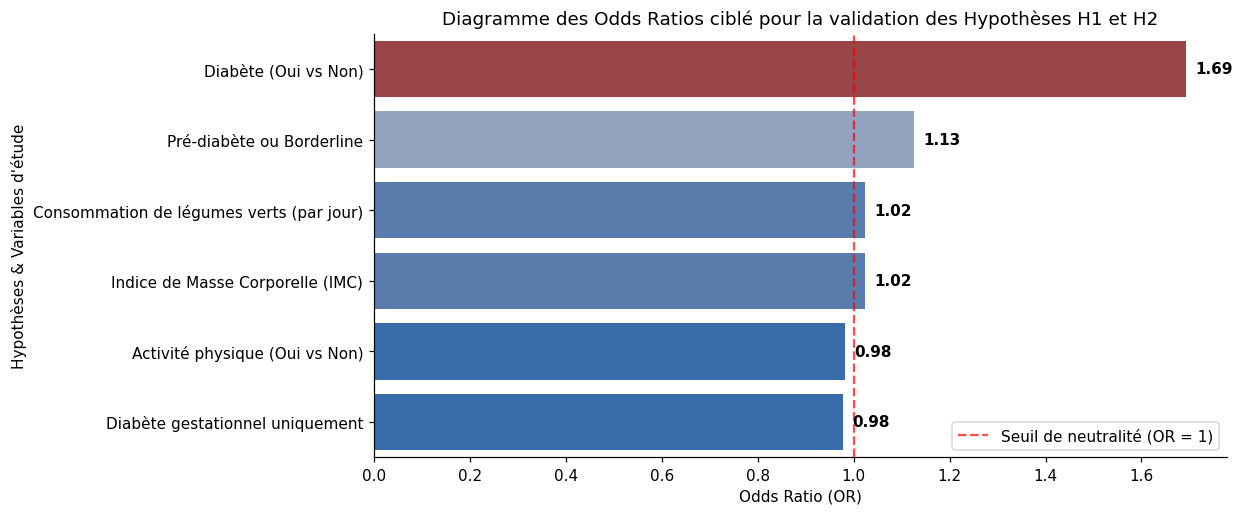

In [39]:
# Figure 9b : Diagramme de forêt (Forest Plot) ciblé sur nos 4 variables d'étude
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    if 'or_df' not in globals() and 'fitted' in globals() and M_LR in fitted:
        lr = fitted[M_LR]
        names = lr.named_steps['prep'].get_feature_names_out()
        coefs = lr.named_steps['clf'].coef_[0]
        or_df = pd.DataFrame({'Variable': names, 'Coefficient': coefs, 'Odds ratio': np.exp(coefs)})
        or_df = or_df.sort_values('Coefficient', key=abs, ascending=False).reset_index(drop=True)
except Exception as e:
    print("Note : Impossible de calculer or_df automatiquement.", e)

if 'or_df' in globals():
    target_variables = [
        'cat__Exercise_Yes',
        'num__Green_Vegetables_Consumption',
        'num__BMI',
        'cat__Diabetes_Yes',
        'cat__Diabetes_No, pre-diabetes or borderline diabetes',
        'cat__Diabetes_Yes, but female told only during pregnancy'
    ]

    plot_or_df = or_df[or_df['Variable'].isin(target_variables)].copy()

    mapping_noms = {
        'cat__Exercise_Yes': "Activité physique (Oui vs Non)",
        'num__Green_Vegetables_Consumption': "Consommation de légumes verts (par jour)",
        'num__BMI': "Indice de Masse Corporelle (IMC)",
        'cat__Diabetes_Yes': "Diabète (Oui vs Non)",
        'cat__Diabetes_No, pre-diabetes or borderline diabetes': "Pré-diabète ou Borderline",
        'cat__Diabetes_Yes, but female told only during pregnancy': "Diabète gestationnel uniquement"
    }
    plot_or_df['Nom_Propre'] = plot_or_df['Variable'].map(mapping_noms)
    plot_or_df = plot_or_df.sort_values('Odds ratio', ascending=False)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.axvline(x=1, color='red', linestyle='--', alpha=0.7, label="Seuil de neutralité (OR = 1)")

    sns.barplot(x='Odds ratio', y='Nom_Propre', data=plot_or_df, ax=ax, palette='vlag', hue='Odds ratio', legend=False)

    for i, row in plot_or_df.reset_index(drop=True).iterrows():
        val = row['Odds ratio']
        ax.text(val + 0.02, i, f"{val:.2f}" if isinstance(val, (int, float)) else str(val), va='center', ha='left', fontsize=10, fontweight='bold')

    ax.set_xlabel('Odds Ratio (OR)')
    ax.set_ylabel('Hypothèses & Variables d\'étude')
    ax.set_title("Diagramme des Odds Ratios ciblé pour la validation des Hypothèses H1 et H2")
    ax.legend(loc='lower right')

save_fig(fig, 'fig09b_odds_ratios_forest_plot', '')

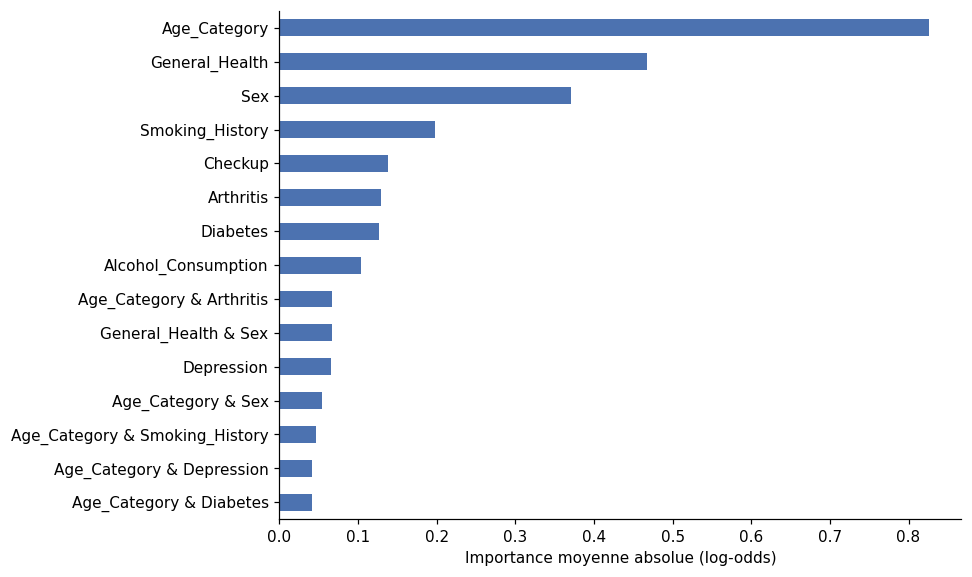

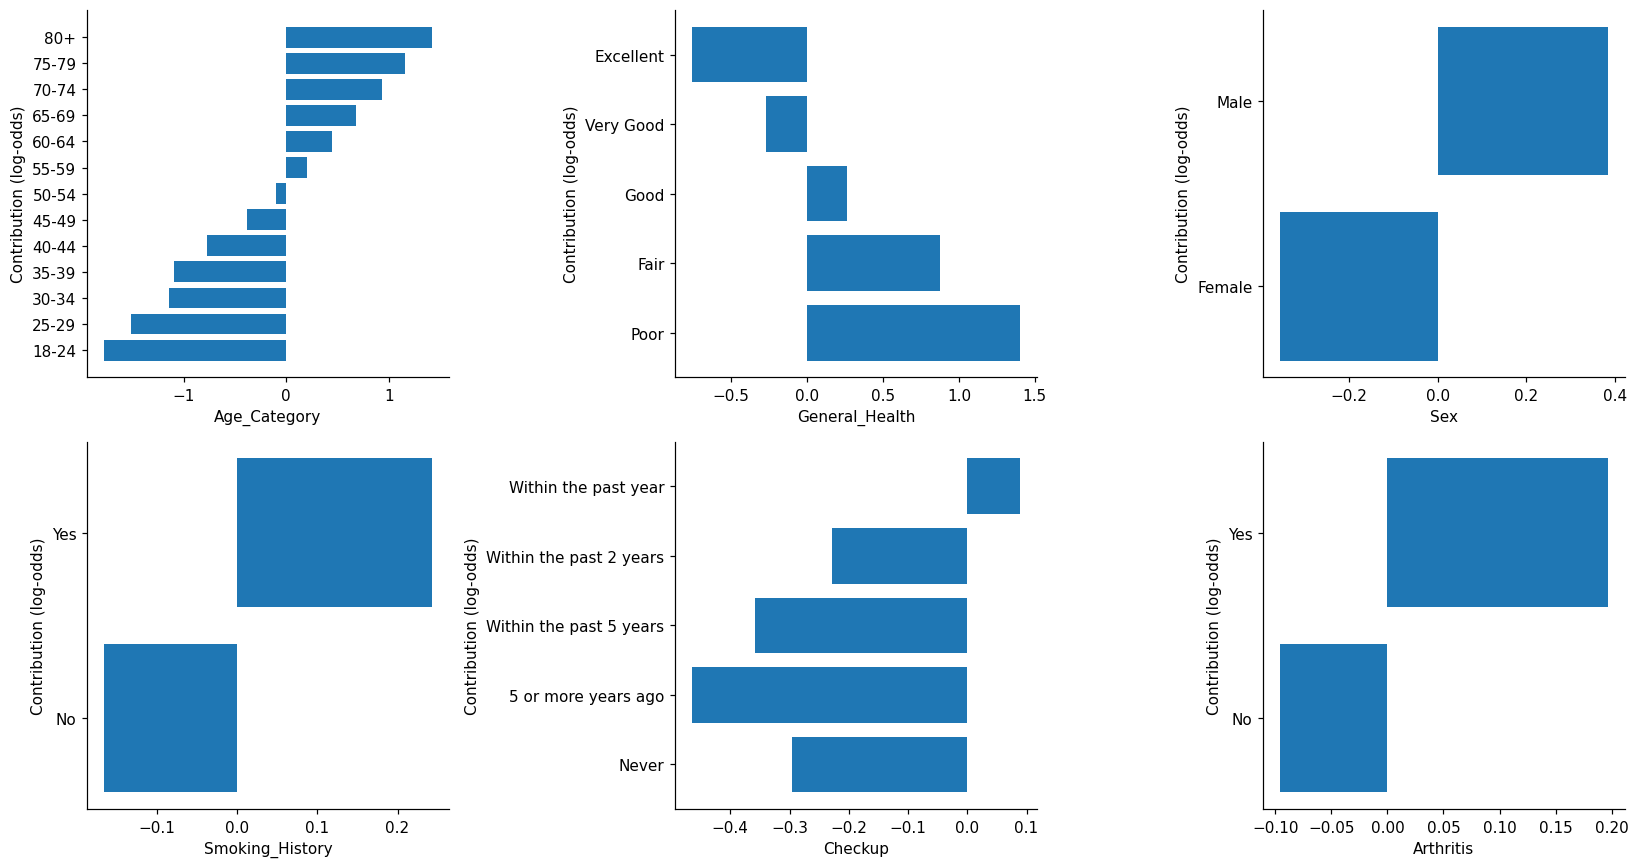

In [40]:
if HAS_EBM and M_EBM in fitted:
    ebm = fitted[M_EBM]
    imp = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values(ascending=False)
    imp.round(4).to_frame('Importance').to_excel(OUT / 'tables' / 'tableau_importances_ebm.xlsx')

    fig, ax = plt.subplots(figsize=(8, 6))
    imp.head(15)[::-1].plot.barh(ax=ax, color='#4C72B0')
    ax.set_xlabel('Importance moyenne absolue (log-odds)')
    save_fig(fig, 'fig10_importances_ebm', '')

    g = ebm.explain_global()
    top = [t for t in imp.index if ' & ' not in t][:6]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, term in zip(axes.ravel(), top):
        d = g.data(ebm.term_names_.index(term))
        x, y = list(d['names']), np.asarray(d['scores'])
        if len(x) == len(y) + 1:
            ax.step(x[:-1], y, where='post')
        else:
            labels = [str(v) for v in x]
            if term in ORDER:
                o = [l for l in ORDER[term] if l in labels]
                y = y[[labels.index(l) for l in o]]
                labels = o
            ax.barh(labels, y)
        ax.set_xlabel(term)
        ax.set_ylabel('Contribution (log-odds)')
    for ax in axes.ravel()[len(top):]:
        ax.axis('off')
    fig.tight_layout()
    save_fig(fig, 'fig11_fonctions_forme_ebm', '')
else:
    print("EBM non disponible : installe la librairie interpret (cellule 1).")

In [41]:
shutil.make_archive('outputs_memoire', 'zip', 'outputs')
print('Archive créée : outputs_memoire.zip')
try:
    from google.colab import files
    files.download('outputs_memoire.zip')
except ImportError:
    pass

Archive créée : outputs_memoire.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>